In [1]:
import pandas as pd
import sqlite3 as sql
import matplotlib.pyplot as plt

In [2]:
conn=sql.connect('chinook.db')

In [3]:
def sql_query(q):
    return pd.read_sql_query(q,conn)

In [4]:
q='select * from sqlite_master'
q

'select * from sqlite_master'

In [5]:
sql_query(q)

,type,name,tbl_name,rootpage,sql
0,table,album,album,2,CREATE TABLE [album]\n(\n [album_id] INTEGE...
1,table,artist,artist,3,CREATE TABLE [artist]\n(\n [artist_id] INTE...
2,table,customer,customer,4,CREATE TABLE [customer]\n(\n [customer_id] ...
3,table,employee,employee,5,CREATE TABLE [employee]\n(\n [employee_id] ...
4,table,genre,genre,6,CREATE TABLE [genre]\n(\n [genre_id] INTEGE...
5,table,invoice,invoice,7,CREATE TABLE [invoice]\n(\n [invoice_id] IN...
6,table,invoice_line,invoice_line,8,CREATE TABLE [invoice_line]\n(\n [invoice_l...
7,table,media_type,media_type,9,CREATE TABLE [media_type]\n(\n [media_type_...
8,table,playlist,playlist,10,CREATE TABLE [playlist]\n(\n [playlist_id] ...
9,table,playlist_track,playlist_track,11,CREATE TABLE [playlist_track]\n(\n [playlis...


In [9]:
sql_query("select* from sqlite_master where type='table'")

,type,name,tbl_name,rootpage,sql
0,table,album,album,2,CREATE TABLE [album]\n(\n [album_id] INTEGE...
1,table,artist,artist,3,CREATE TABLE [artist]\n(\n [artist_id] INTE...
2,table,customer,customer,4,CREATE TABLE [customer]\n(\n [customer_id] ...
3,table,employee,employee,5,CREATE TABLE [employee]\n(\n [employee_id] ...
4,table,genre,genre,6,CREATE TABLE [genre]\n(\n [genre_id] INTEGE...
5,table,invoice,invoice,7,CREATE TABLE [invoice]\n(\n [invoice_id] IN...
6,table,invoice_line,invoice_line,8,CREATE TABLE [invoice_line]\n(\n [invoice_l...
7,table,media_type,media_type,9,CREATE TABLE [media_type]\n(\n [media_type_...
8,table,playlist,playlist,10,CREATE TABLE [playlist]\n(\n [playlist_id] ...
9,table,playlist_track,playlist_track,11,CREATE TABLE [playlist_track]\n(\n [playlis...


## Q1. Write a query to list the top 10 genres with the highest number of tracks. (Show in bar plot)

                genre  total_tracks
0                Rock          1297
1               Latin           579
2               Metal           374
3  Alternative & Punk           332
4                Jazz           130
5            TV Shows            93
6               Blues            81
7           Classical            74
8               Drama            64
9            R&B/Soul            61


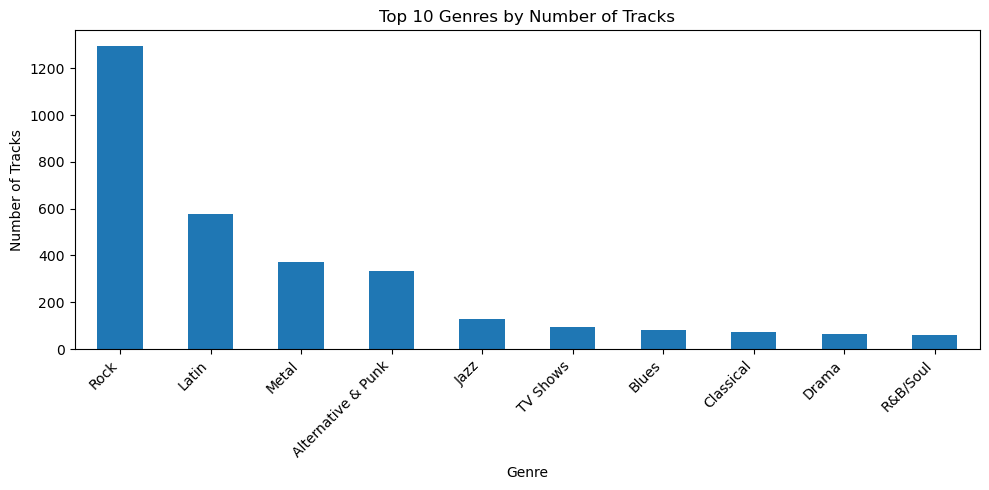

In [31]:
q = '''
Select g.name as genre, count(t.track_id) as total_tracks
from genre g
join track t on g.genre_id = t.genre_id
group by g.genre_id, g.name
order by total_tracks desc limit 10;
'''
df1 = sql_query(q)
print(df1)

df1.plot(
    x="genre",
    y="total_tracks",
    kind="bar",
    legend=False,
    figsize=(10, 5)
)
plt.title("Top 10 Genres by Number of Tracks")
plt.xlabel("Genre")
plt.ylabel("Number of Tracks")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## Q2. Write a query to list the top 10 albums that contain the most tracks.

In [23]:
q = '''
select al.title AS album, ar.name AS artist, count(t.track_id) AS total_tracks
from album al
join artist ar on al.artist_id = ar.artist_id
join track t on al.album_id = t.album_id
group by al.album_id, al.title, ar.name
order by total_tracks desc limit 10;
'''
sql_query(q)


,album,artist,total_tracks
0,Greatest Hits,Lenny Kravitz,57
1,Minha Historia,Chico Buarque,34
2,Unplugged,Eric Clapton,30
3,"Lost, Season 3",Lost,26
4,"Lost, Season 1",Lost,25
5,"The Office, Season 3",The Office,25
6,My Way: The Best Of Frank Sinatra [Disc 1],Frank Sinatra,24
7,"Lost, Season 2",Lost,24
8,"Battlestar Galactica (Classic), Season 1",Battlestar Galactica (Classic),24
9,Afrociberdelia,Chico Science & Nação Zumbi,23


## Q3. Write a query to find the top 10 customers who spent the most money.

In [29]:
q= '''select c.customer_id, c.first_name || ' ' || c.last_name AS customer_name, c.country,
    round(sum(il.unit_price * il.quantity), 2) as total_spent
from customer c
join invoice i on c.customer_id = i.customer_id
join invoice_line il ON i.invoice_id = il.invoice_id
group by c.customer_id, customer_name, c.country
order by total_spent desc limit 10;
'''
sql_query(q)


,customer_id,customer_name,country,total_spent
0,5,František Wichterlová,Czech Republic,144.54
1,6,Helena Holý,Czech Republic,128.70
2,46,Hugh O'Reilly,Ireland,114.84
3,58,Manoj Pareek,India,111.87
4,1,Luís Gonçalves,Brazil,108.90
5,13,Fernanda Ramos,Brazil,106.92
6,34,João Fernandes,Portugal,102.96
7,3,François Tremblay,Canada,99.99
8,42,Wyatt Girard,France,99.99
9,17,Jack Smith,USA,98.01


## Q4. Write a query to find the top 5 artists who generated the highest revenue from track sales.

In [33]:
q = '''select ar.name as artist,
    round(sum(il.unit_price * il.quantity), 2) as revenue
from artist ar
join album al on ar.artist_id = al.artist_id
join track t on al.album_id = t.album_id
join invoice_line il on t.track_id = il.track_id
group by ar.artist_id, ar.name
order by revenue desc limit 5;
'''
sql_query(q)

,artist,revenue
0,Queen,190.08
1,Jimi Hendrix,185.13
2,Nirvana,128.70
3,Red Hot Chili Peppers,128.70
4,Pearl Jam,127.71


## Q5. Countries by Average Revenue per Invoice

In [36]:
q = '''
SELECT
    billing_country as country,
    count(invoice_id) as total_invoices,
    round(avg(total), 2) as average_revenue_per_invoice,
    round(sum(total), 2) as total_revenue
from invoice
group by billing_country
order by average_revenue_per_invoice DESC;
'''
sql_query(q)

,country,total_invoices,average_revenue_per_invoice,total_revenue
0,Czech Republic,30,9.11,273.24
1,Spain,11,8.91,98.01
2,Ireland,13,8.83,114.84
3,United Kingdom,28,8.77,245.52
4,India,21,8.72,183.15
5,Belgium,7,8.63,60.39
6,Germany,41,8.16,334.62
7,Australia,10,8.12,81.18
8,Norway,9,8.03,72.27
9,USA,131,7.94,1040.49


## Q6. Write a query to find the media type with number of tracks.

In [41]:
q = '''
select m.name as media_type, count(t.track_id) as total_tracks
from media_type m
left join track t on m.media_type_id = t.media_type_id
group by m.media_type_id, m.name
order by total_tracks desc;
'''
sql_query(q)

,media_type,total_tracks
0,MPEG audio file,3034
1,Protected AAC audio file,237
2,Protected MPEG-4 video file,214
3,AAC audio file,11
4,Purchased AAC audio file,7


## Q7. Which artists have released tracks in more than one genre?

In [42]:
q = '''select ar.name as artist, count(distinct t.genre_id) as total_genres
from artist ar
join album al on ar.artist_id = al.artist_id
join track t on al.album_id = t.album_id
where t.genre_id is not null
group by ar.artist_id, ar.name
having count (distinct t.genre_id) > 1
order by  total_genres desc, artist;
'''
sql_query(q)


,artist,total_genres
0,Iron Maiden,4
1,Audioslave,3
2,Battlestar Galactica,3
3,Gilberto Gil,3
4,Jamiroquai,3
5,Lenny Kravitz,3
6,Various Artists,3
7,Amy Winehouse,2
8,Antônio Carlos Jobim,2
9,Eric Clapton,2


## Q8. Write a query to list the top 10 longest tracks by duration.

In [46]:
q8 = ''' select  name as track_name,
    round(milliseconds / 60000.0, 2) AS duration_minutes,
    milliseconds AS duration_milliseconds
from track
order by milliseconds desc limit 10;
'''
sql_query(q8)


,track_name,duration_minutes,duration_milliseconds
0,Occupation / Precipice,88.12,5286953
1,Through a Looking Glass,84.81,5088838
2,"Greetings from Earth, Pt. 1",49.34,2960293
3,The Man With Nine Lives,49.28,2956998
4,"Battlestar Galactica, Pt. 2",49.27,2956081
5,"Battlestar Galactica, Pt. 1",49.21,2952702
6,Murder On the Rising Star,48.93,2935894
7,"Battlestar Galactica, Pt. 3",48.80,2927802
8,Take the Celestra,48.79,2927677
9,Fire In Space,48.78,2926593


## Q10. Revenue by Genre (Rock, Latin, Metal) in Each Country (Stacked Column Chart)

           country  genre  revenue
0        Argentina  Latin     1.98
1        Argentina  Metal     1.98
2        Argentina   Rock    10.89
3        Australia  Latin     1.98
4        Australia  Metal    13.86
..             ...    ...      ...
65             USA  Metal   122.76
66             USA   Rock   555.39
67  United Kingdom  Latin     6.93
68  United Kingdom  Metal    30.69
69  United Kingdom   Rock   164.34

[70 rows x 3 columns]


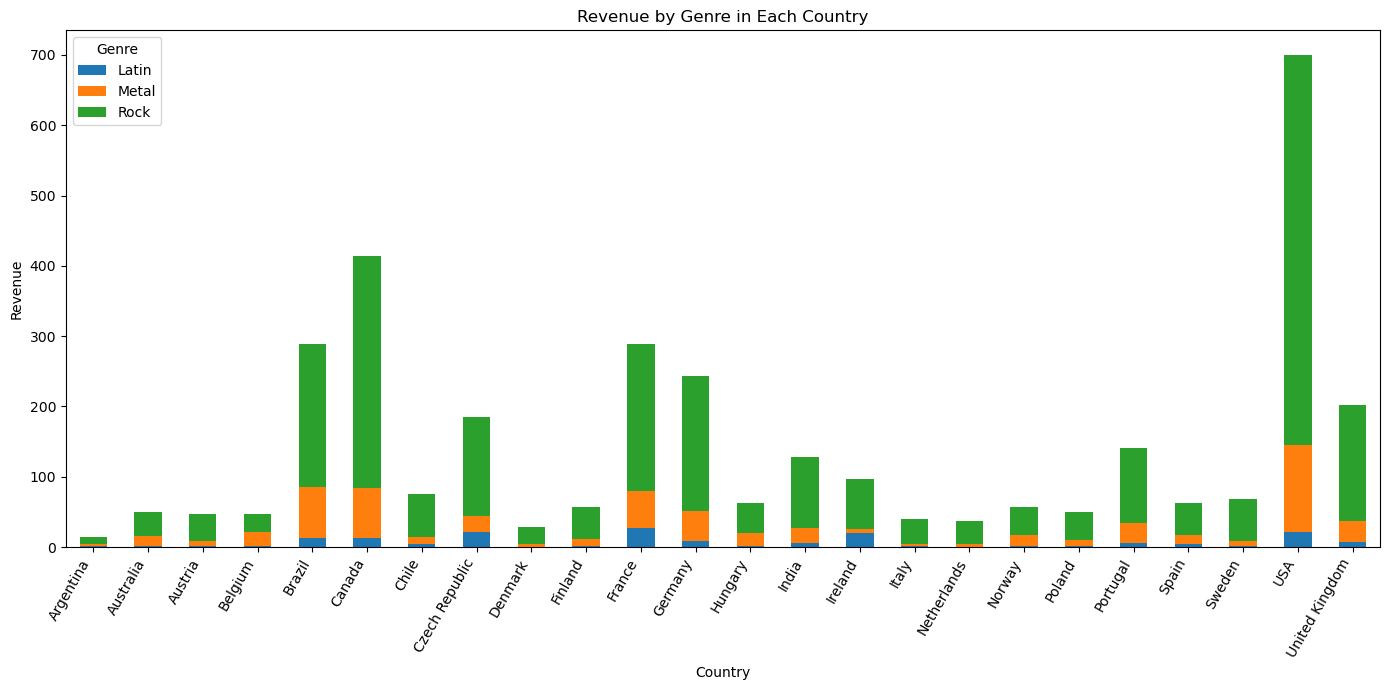

In [50]:
q= '''select i.billing_country as country, g.name as genre,
    round(sum(il.unit_price * il.quantity), 2) as revenue
from invoice i
join invoice_line il on i.invoice_id = il.invoice_id
join track t on il.track_id = t.track_id
join genre g on t.genre_id = g.genre_id
where g.name in ('Rock', 'Latin', 'Metal')
group by i.billing_country, g.name
order by i.billing_country, g.name;
'''

df10 = sql_query(q)
print(df10)
pivot_df = df10.pivot(
    index="country",
    columns="genre",
    values="revenue"
).fillna(0)

pivot_df.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 7)
)

plt.title("Revenue by Genre in Each Country")
plt.xlabel("Country")
plt.ylabel("Revenue")
plt.xticks(rotation=60, ha="right")
plt.legend(title="Genre")
plt.tight_layout()
plt.show()